In [ ]:
# Load the panel straight from the GitHub repo (no upload needed)
DATA_URL = "https://raw.githubusercontent.com/penelopemichou/austerity-ml/main/data/panel_master.csv"

My predictions (before running)

1. Rows that survive: about 700
2. Slope (positive or negative): negative
3. R² (almost nothing / a little / a lot): almost nothing
4. Country at the far right: Greece

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(DATA_URL)
print(df.shape)              # (rows, columns): expect about (780, ...)
print(df.columns.tolist())   # the exact column names
df.head()

(780, 22)
['country', 'year', 'tfp', 'outputperworker', 'gfcf_public', 'gfcf_private', 'unemployment', 'real_compensation', 'exports', 'rd_intensity', 'gdp_growth', 'debt_gdp', 'long_rate', 'inflation', 'trade_open', 'net_exports_gdp', 'gini_disp', 'gini_disp_se', 'consumer_confidence', 'n_months', 'capb_main', 'dcapb_main']


,country,year,tfp,outputperworker,gfcf_public,gfcf_private,unemployment,real_compensation,exports,rd_intensity,...,long_rate,inflation,trade_open,net_exports_gdp,gini_disp,gini_disp_se,consumer_confidence,n_months,capb_main,dcapb_main
0,Austria,1995,83.3,73.1,3.9,21.773735,4.5,89.1,104.6,NaN,...,7.1,NaN,47.960351,-0.838734,26.7,0.80,-10.233333,3.0,-1.9,NaN
1,Austria,1996,83.2,74.4,3.7,22.258953,4.9,89.5,104.2,NaN,...,6.3,-0.723589,48.862365,-1.118985,26.2,0.79,-14.558333,12.0,-0.3,1.6
2,Austria,1997,83.5,75.5,3.0,22.523962,4.9,89.1,104.5,NaN,...,5.7,-1.311953,51.369113,-0.547645,26.1,0.85,-14.241667,12.0,1.5,1.8
3,Austria,1998,85.8,77.3,2.9,22.631848,4.7,91.0,103.2,NaN,...,4.7,0.000000,52.928723,-0.141143,26.2,0.95,-7.233333,12.0,0.8,-0.7
4,Austria,1999,87.3,79.1,2.9,22.205810,4.0,92.6,102.3,NaN,...,4.7,0.738552,54.233254,0.306018,26.1,0.95,-3.458333,12.0,0.1,-0.7


In [4]:
COUNTRY = "country"
YEAR    = "year"
DCAPB   = "dcapb_main"   # ΔCAPB, pp of GDP
TFP     = "tfp"          # TFP index level
H = 2

df = df.sort_values([COUNTRY, YEAR]).copy()
df["log_tfp"] = np.log(df[TFP])

lead = df.groupby(COUNTRY)["log_tfp"].shift(-H)   # log TFP at t+2, same country
lag1 = df.groupby(COUNTRY)["log_tfp"].shift(1)    # log TFP at t-1
df["y"] = 100 * (lead - lag1)                     # cumulative % growth, t-1 -> t+2

data = df[[COUNTRY, YEAR, DCAPB, "y"]].dropna()
x = data[DCAPB].to_numpy()
y = data["y"].to_numpy()
print(len(data), "usable rows")
data.describe()

691 usable rows


,year,dcapb_main,y
count,691.000000,691.000000,691.000000
mean,2009.182344,-0.061071,3.617404
std,7.717008,2.290783,5.420660
min,1996.000000,-18.800000,-16.900851
25%,2003.000000,-1.000000,0.497306
50%,2009.000000,-0.100000,3.080038
75%,2016.000000,0.800000,6.049719
max,2022.000000,18.200000,25.529612


In [5]:
def compute_cost(x, y, w, b):
    m = len(x)
    f_wb = w * x + b
    return np.sum((f_wb - y) ** 2) / (2 * m)

def compute_gradient(x, y, w, b):
    m = len(x)
    err = (w * x + b) - y
    dj_dw = np.sum(err * x) / m
    dj_db = np.sum(err) / m
    return dj_dw, dj_db

def gradient_descent(x, y, w=0.0, b=0.0, alpha=0.01, iters=5000):
    J_history = []
    for i in range(iters):
        dj_dw, dj_db = compute_gradient(x, y, w, b)
        w = w - alpha * dj_dw          # step downhill in w
        b = b - alpha * dj_db          # step downhill in b
        J_history.append(compute_cost(x, y, w, b))
    return w, b, J_history

w, b, J_hist = gradient_descent(x, y)
print(f"Gradient descent: w = {w:.3f}, b = {b:.3f}")

w_ols, b_ols = np.polyfit(x, y, 1)     # closed-form OLS, as a check
print(f"OLS check:        w = {w_ols:.3f}, b = {b_ols:.3f}")

r2 = 1 - np.sum((w*x + b - y)**2) / np.sum((y - y.mean())**2)
print(f"R² = {r2:.3f}")

Gradient descent: w = -0.198, b = 3.605
OLS check:        w = -0.198, b = 3.605
R² = 0.007


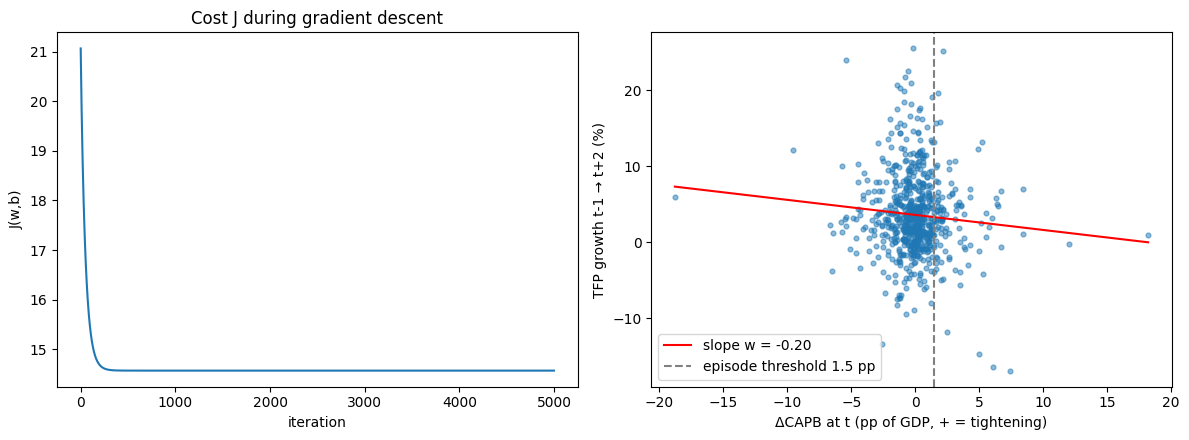

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

ax[0].plot(J_hist)
ax[0].set_title("Cost J during gradient descent")
ax[0].set_xlabel("iteration"); ax[0].set_ylabel("J(w,b)")

ax[1].scatter(x, y, s=12, alpha=0.5)
xs = np.linspace(x.min(), x.max(), 100)
ax[1].plot(xs, w*xs + b, color="red", label=f"slope w = {w:.2f}")
ax[1].axvline(1.5, ls="--", color="grey", label="episode threshold 1.5 pp")
ax[1].set_xlabel("ΔCAPB at t (pp of GDP, + = tightening)")
ax[1].set_ylabel(f"TFP growth t-1 → t+{H} (%)")
ax[1].legend()
plt.tight_layout(); plt.show()

In [7]:
# Fixed effects by "demeaning": remove each country's average and each year's average.
# We repeat it a few times because some early years are missing (unbalanced panel).
d = data.copy()
for col in [DCAPB, "y"]:
    v = d[col].copy()
    for i in range(50):
        v = v - v.groupby(d[COUNTRY]).transform("mean")   # remove country average
        v = v - v.groupby(d[YEAR]).transform("mean")      # remove year average
    d[col + "_fe"] = v

x_fe = d[DCAPB + "_fe"].to_numpy()
y_fe = d["y_fe"].to_numpy()

# Same gradient descent as Cell 4, just on the demeaned data
w_fe, b_fe, J_fe = gradient_descent(x_fe, y_fe)
r2_fe = 1 - np.sum((w_fe*x_fe + b_fe - y_fe)**2) / np.sum((y_fe - y_fe.mean())**2)

print(f"Pooled slope (Cell 4):      w = {w:.3f}")
print(f"Fixed-effects slope:        w = {w_fe:.3f}")
print(f"R² within countries/years:  {r2_fe:.3f}")

Pooled slope (Cell 4):      w = -0.198
Fixed-effects slope:        w = -0.268
R² within countries/years:  0.022


6. Linear model's effect per episode vs thesis −1.5 %: smaller

In [8]:
ep = data[DCAPB] >= 1.5                     # True in episode years (thesis definition)
avg_ep = data.loc[ep, DCAPB].mean()         # how big an average episode is

print(f"Episode-years in this sample:        {ep.sum()}")
print(f"Average ΔCAPB in an episode year:    {avg_ep:.2f} pp")
print(f"Linear FE model, effect per episode: {w_fe * avg_ep:.2f} %")
print(f"Your thesis (LP, h = 2):             -1.50 %")

Episode-years in this sample:        106
Average ΔCAPB in an episode year:    3.31 pp
Linear FE model, effect per episode: -0.89 %
Your thesis (LP, h = 2):             -1.50 %


7. On unseen countries, does the line beat "always predict the average"?:
barely better

In [9]:
# 1. Hide 6 countries (fixed seed = same "random" pick every time you run it)
rng = np.random.default_rng(42)
countries = data[COUNTRY].unique()
test_countries = rng.choice(countries, size=6, replace=False)
print("Hidden countries:", sorted(test_countries))

train = data[~data[COUNTRY].isin(test_countries)]
test  = data[ data[COUNTRY].isin(test_countries)]

# 2. Train the line on the 20 visible countries only
w_tr, b_tr, _ = gradient_descent(train[DCAPB].to_numpy(), train["y"].to_numpy())

# 3. Predict the hidden countries
x_te, y_te = test[DCAPB].to_numpy(), test["y"].to_numpy()
pred_model    = w_tr * x_te + b_tr
pred_baseline = np.full_like(y_te, train["y"].mean())   # "always predict the average"

# 4. Compare errors (mean squared error: lower = better)
mse_model    = np.mean((pred_model - y_te) ** 2)
mse_baseline = np.mean((pred_baseline - y_te) ** 2)
print(f"Rows: train {len(train)}, test {len(test)}")
print(f"Error, linear model: {mse_model:.2f}")
print(f"Error, baseline:     {mse_baseline:.2f}")
print(f"Improvement over baseline: {100*(1 - mse_model/mse_baseline):.1f} %")

Hidden countries: ['Belgium', 'Greece', 'Lithuania', 'Malta', 'Slovakia', 'Spain']
Rows: train 530, test 161
Error, linear model: 30.34
Error, baseline:     30.72
Improvement over baseline: 1.2 %


Learning log – Session 1 (30 Oct 2026)
- Gradient descent finds the same line as OLS (w = −0.198). Fixed effects make it −0.268.
- Significant ≠ predictive: within-country R² is 0.022, and on 6 unseen countries the model beats the mean by only 1.2 %.
- A straight line gives −0.89 % per episode vs −1.50 % in my thesis LP: a threshold effect gets diluted by a linear model.